# Practical Assignment 2: Problem Solving Through Search

**Subject:** Artificial Intelligence / Machine Learning  
**Practical:** Evaluation of Uninformed, Informed, Local Search and Constraint Satisfaction algorithms

**Name :- Avinash Singh**
**Div:-E   Batch:-E1 Roll NO:- 312**
**PRN :- 202401040311** 

**GITHUB REPO** :- https://github.com/avinashsingh539/AIML_CA_IA_Labs


## Aim
To implement and compare different search-based problem-solving techniques using suitable benchmark problems, and evaluate them using solution quality, number of explored states and execution time.


| Search family | Algorithms | Benchmark problem |
|---|---|---|
| Uninformed | Breadth-First Search (BFS), Depth-First Search (DFS), Uniform Cost Search (UCS) | Zachary's Karate Club graph |
| Informed | Greedy Best-First Search, A* | Same graph, with an admissible heuristic |
| Local search | Hill Climbing | N-Queens |
| Constraint satisfaction | Backtracking, MRV + Forward Checking | Australia map colouring |





## 1. Import libraries and setup



In [23]:
import heapq
import math
import random
import time
from collections import deque

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset: Zachary's Karate Club Network

Zachary's Karate Club is a classic social-network benchmark. Each node represents a club member and each edge represents a social connection observed in the study. We use the graph topology for route-finding experiments. Edge costs are assigned reproducibly from node IDs so that BFS (fewest edges) and cost-based methods (lowest total cost) can be meaningfully distinguished. These costs are experimental weights, not measured travel distances.

Dataset source: NetworkX built-in `karate_club_graph()` dataset. Background: W. W. Zachary, *An Information Flow Model for Conflict and Fission in Small Groups* (1977).

Number of nodes: 34
Number of undirected edges: 78
First five edges:
[(0, 1, 3), (0, 2, 5), (0, 3, 7), (0, 4, 9), (0, 5, 2)]


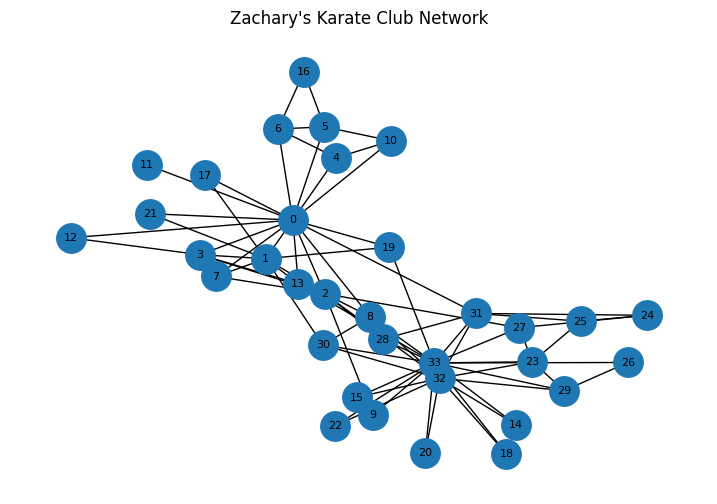

In [24]:
G = nx.karate_club_graph()

# Give each undirected edge a deterministic positive experimental cost.
for u, v in G.edges():
    G[u][v]["cost"] = 1 + ((u * 7 + v * 11) % 9)

print(f"Number of nodes: {G.number_of_nodes()}")
print(f"Number of undirected edges: {G.number_of_edges()}")
print("First five edges:")
print([(u, v, G[u][v]["cost"]) for u, v in list(G.edges())[:5]])

plt.figure(figsize=(9, 6))
pos = nx.spring_layout(G, seed=RANDOM_SEED)
nx.draw_networkx(G, pos, node_size=450, font_size=8, with_labels=True)
plt.title("Zachary's Karate Club Network")
plt.axis("off")
plt.show()

In [25]:
# Save a simple edge-list copy so the dataset used in this practical is included in the repository.
edge_rows = [(u, v, G[u][v]["cost"]) for u, v in G.edges()]
edge_df = pd.DataFrame(edge_rows, columns=["source", "target", "experimental_cost"])
edge_df.to_csv("data/karate_club_edges.csv", index=False)
edge_df.head()

,source,target,experimental_cost
0,0,1,3
1,0,2,5
2,0,3,7
3,0,4,9
4,0,5,2


## 3. Search problem and evaluation metrics

We will find a route from node **0** to node **33**. The graph is undirected. BFS and DFS treat every edge as one step; UCS and A* use the positive `cost` attached to each edge.

For each algorithm we record:

- **Path:** sequence of nodes returned by the algorithm.
- **Path cost:** sum of edge costs along the returned path.
- **Path length:** number of edges in the path.
- **Expanded nodes:** number of nodes removed from the frontier for processing.
- **Execution time:** measured in milliseconds on this run.



In [26]:
START_NODE = 0
GOAL_NODE = 33

# A helper used by all graph-search implementations.
def calculate_path_cost(graph, path):
    if not path or len(path) == 1:
        return 0
    return sum(graph[u][v]["cost"] for u, v in zip(path, path[1:]))

# An admissible heuristic for A*: unweighted hop distance multiplied by
# the minimum possible edge cost. It can never exceed the true weighted cost.
MIN_EDGE_COST = min(data["cost"] for _, _, data in G.edges(data=True))

def heuristic(node, goal):
    return nx.shortest_path_length(G, source=node, target=goal) * MIN_EDGE_COST

print("Start:", START_NODE, "Goal:", GOAL_NODE)
print("Minimum edge cost:", MIN_EDGE_COST)
print("Heuristic at start:", heuristic(START_NODE, GOAL_NODE))

Start: 0 Goal: 33
Minimum edge cost: 1
Heuristic at start: 2


## 4. Uninformed search algorithms

Uninformed algorithms do not use an estimate of the distance to the goal.

- **BFS** explores level by level and returns a path with the fewest edges when all edges are treated equally.
- **DFS** follows one branch as far as possible before backtracking. It does not guarantee the shortest path.
- **UCS** expands the frontier node with the lowest accumulated path cost and is optimal when edge costs are non-negative.

In [27]:
def reconstruct_path(parent, goal):
    if goal not in parent:
        return None
    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = parent[current]
    return path[::-1]


def breadth_first_search(graph, start, goal):
    frontier = deque([start])
    parent = {start: None}
    expanded = 0
    while frontier:
        node = frontier.popleft()
        expanded += 1
        if node == goal:
            break
        for neighbor in sorted(graph.neighbors(node)):
            if neighbor not in parent:
                parent[neighbor] = node
                frontier.append(neighbor)
    path = reconstruct_path(parent, goal)
    return {"algorithm": "BFS", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": calculate_path_cost(graph, path) if path else None}


def depth_first_search(graph, start, goal):
    stack = [start]
    parent = {start: None}
    expanded = 0
    while stack:
        node = stack.pop()
        expanded += 1
        if node == goal:
            break
        # Reverse order makes the traversal deterministic with a LIFO stack.
        for neighbor in sorted(graph.neighbors(node), reverse=True):
            if neighbor not in parent:
                parent[neighbor] = node
                stack.append(neighbor)
    path = reconstruct_path(parent, goal)
    return {"algorithm": "DFS", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": calculate_path_cost(graph, path) if path else None}


def uniform_cost_search(graph, start, goal):
    frontier = [(0, start)]
    parent = {start: None}
    best_cost = {start: 0}
    expanded = 0
    while frontier:
        cost_so_far, node = heapq.heappop(frontier)
        if cost_so_far != best_cost.get(node):
            continue
        expanded += 1
        if node == goal:
            break
        for neighbor in graph.neighbors(node):
            new_cost = cost_so_far + graph[node][neighbor]["cost"]
            if new_cost < best_cost.get(neighbor, math.inf):
                best_cost[neighbor] = new_cost
                parent[neighbor] = node
                heapq.heappush(frontier, (new_cost, neighbor))
    path = reconstruct_path(parent, goal)
    return {"algorithm": "UCS", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": calculate_path_cost(graph, path) if path else None}


def run_and_measure(function, *args):
    start_time = time.perf_counter()
    result = function(*args)
    result["time_ms"] = (time.perf_counter() - start_time) * 1000
    return result

uninformed_results = [
    run_and_measure(breadth_first_search, G, START_NODE, GOAL_NODE),
    run_and_measure(depth_first_search, G, START_NODE, GOAL_NODE),
    run_and_measure(uniform_cost_search, G, START_NODE, GOAL_NODE),
]
for result in uninformed_results:
    print(result["algorithm"], "path:", result["path"],
          "| cost:", result["path_cost"], "| expanded:", result["expanded"])


BFS path: [0, 8, 33] | cost: 14 | expanded: 24
DFS path: [0, 1, 30, 33] | cost: 15 | expanded: 16
UCS path: [0, 19, 33] | cost: 5 | expanded: 9


## 5. Informed search algorithms

Informed search uses a heuristic to guide exploration.

- **Greedy Best-First Search** chooses the node that appears closest to the goal according to the heuristic. It can be fast, but it does not guarantee the cheapest path.
- **A*** uses `f(n) = g(n) + h(n)`, where `g(n)` is the cost already travelled and `h(n)` is the estimated remaining cost. With an admissible heuristic and non-negative edge costs, A* finds an optimal path.


In [28]:
def greedy_best_first_search(graph, start, goal):
    frontier = [(heuristic(start, goal), start)]
    parent = {start: None}
    visited = set()
    expanded = 0
    while frontier:
        _, node = heapq.heappop(frontier)
        if node in visited:
            continue
        visited.add(node)
        expanded += 1
        if node == goal:
            break
        for neighbor in graph.neighbors(node):
            if neighbor not in visited and neighbor not in parent:
                parent[neighbor] = node
                heapq.heappush(frontier, (heuristic(neighbor, goal), neighbor))
    path = reconstruct_path(parent, goal)
    return {"algorithm": "Greedy Best-First", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": calculate_path_cost(graph, path) if path else None}


def a_star_search(graph, start, goal):
    frontier = [(heuristic(start, goal), 0, start)]
    parent = {start: None}
    best_g = {start: 0}
    expanded = 0
    while frontier:
        _, g_cost, node = heapq.heappop(frontier)
        if g_cost != best_g.get(node):
            continue
        expanded += 1
        if node == goal:
            break
        for neighbor in graph.neighbors(node):
            new_g = g_cost + graph[node][neighbor]["cost"]
            if new_g < best_g.get(neighbor, math.inf):
                best_g[neighbor] = new_g
                parent[neighbor] = node
                f_cost = new_g + heuristic(neighbor, goal)
                heapq.heappush(frontier, (f_cost, new_g, neighbor))
    path = reconstruct_path(parent, goal)
    return {"algorithm": "A*", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": calculate_path_cost(graph, path) if path else None}

informed_results = [
    run_and_measure(greedy_best_first_search, G, START_NODE, GOAL_NODE),
    run_and_measure(a_star_search, G, START_NODE, GOAL_NODE),
]
for result in informed_results:
    print(result["algorithm"], "path:", result["path"],
          "| cost:", result["path_cost"], "| expanded:", result["expanded"])


Greedy Best-First path: [0, 8, 33] | cost: 14 | expanded: 3
A* path: [0, 19, 33] | cost: 5 | expanded: 5


## 6. Compare graph-search results

The table combines all five graph-search algorithms. Notice that BFS optimizes the number of edges, while UCS and A* optimize the assigned edge cost. Therefore, a BFS path can contain fewer edges but have a higher total cost.

,algorithm,path_length,path_cost,expanded,time_ms
0,DFS,3,15,16,0.0403
1,BFS,2,14,24,0.0763
2,UCS,2,5,9,0.0808
3,A*,2,5,5,0.3017
4,Greedy Best-First,2,14,3,0.3107


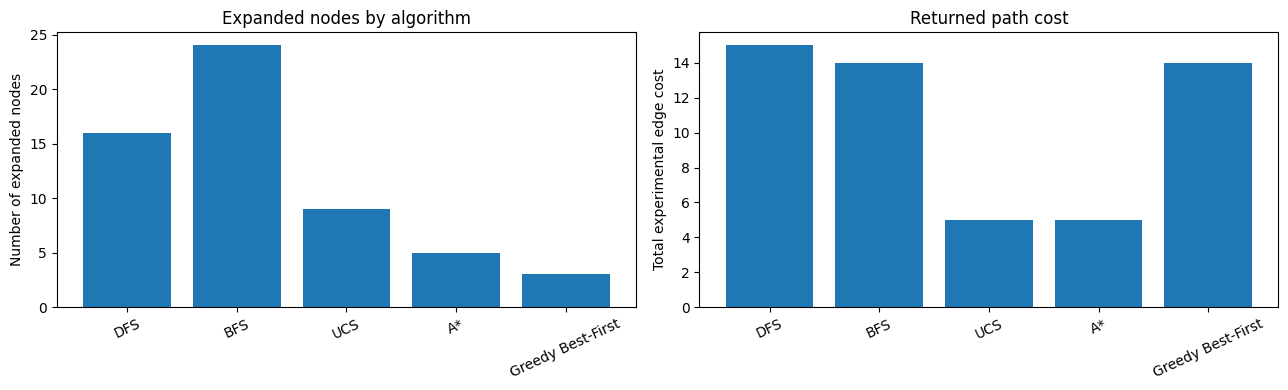

In [29]:
graph_results = uninformed_results + informed_results
search_comparison = pd.DataFrame([
    {key: result[key] for key in ["algorithm", "path_length", "path_cost", "expanded", "time_ms"]}
    for result in graph_results
])
search_comparison = search_comparison.sort_values("time_ms").reset_index(drop=True)
display(search_comparison.round({"time_ms": 4}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(search_comparison["algorithm"], search_comparison["expanded"])
axes[0].set_title("Expanded nodes by algorithm")
axes[0].set_ylabel("Number of expanded nodes")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(search_comparison["algorithm"], search_comparison["path_cost"])
axes[1].set_title("Returned path cost")
axes[1].set_ylabel("Total experimental edge cost")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 7. Local search: N-Queens problem

In the N-Queens problem, one queen is placed in each column of an `N × N` chessboard. The objective is to place them so that no two queens attack each other. We represent a board as a list: the index is the column and the value is the queen's row.

The objective function is the number of pairs of queens that attack each other. A solution has a conflict count of zero. We compare:

- **Hill Climbing:** repeatedly moves to a better neighboring state. It can get stuck in a local minimum or plateau.
- **Simulated Annealing:** sometimes accepts a worse move early in the search, helping it escape local minima. The chance of accepting worse moves decreases as the temperature cools.

In [30]:
def queen_conflicts(state):
    conflicts = 0
    n = len(state)
    for c1 in range(n):
        for c2 in range(c1 + 1, n):
            if state[c1] == state[c2] or abs(state[c1] - state[c2]) == abs(c1 - c2):
                conflicts += 1
    return conflicts


def random_neighbor(state, rng):
    n = len(state)
    neighbor = state.copy()
    col = rng.randrange(n)
    choices = [row for row in range(n) if row != state[col]]
    neighbor[col] = rng.choice(choices)
    return neighbor


def hill_climbing(n=8, seed=0, max_steps=500):
    rng = random.Random(seed)
    state = [rng.randrange(n) for _ in range(n)]
    steps = 0
    for steps in range(1, max_steps + 1):
        current_score = queen_conflicts(state)
        if current_score == 0:
            break
        neighbors = []
        for col in range(n):
            for row in range(n):
                if row != state[col]:
                    candidate = state.copy()
                    candidate[col] = row
                    neighbors.append(candidate)
        best_score = min(queen_conflicts(candidate) for candidate in neighbors)
        best_candidates = [candidate for candidate in neighbors if queen_conflicts(candidate) == best_score]
        if best_score >= current_score:
            break
        state = rng.choice(best_candidates)
    return {"algorithm": "Hill Climbing", "conflicts": queen_conflicts(state), "steps": steps,
            "solved": queen_conflicts(state) == 0, "state": state}


def simulated_annealing(n=8, seed=0, max_steps=5000, initial_temp=10.0, cooling=0.995):
    rng = random.Random(seed)
    state = [rng.randrange(n) for _ in range(n)]
    score = queen_conflicts(state)
    temperature = initial_temp
    steps = 0
    for steps in range(1, max_steps + 1):
        if score == 0:
            break
        candidate = random_neighbor(state, rng)
        candidate_score = queen_conflicts(candidate)
        delta = candidate_score - score
        if delta < 0 or rng.random() < math.exp(-delta / max(temperature, 1e-12)):
            state, score = candidate, candidate_score
        temperature *= cooling
    return {"algorithm": "Simulated Annealing", "conflicts": queen_conflicts(state), "steps": steps,
            "solved": queen_conflicts(state) == 0, "state": state}

# Run multiple trials because local-search results depend on the initial state.
N_QUEENS = 8
TRIALS = 30
local_rows = []
for trial in range(TRIALS):
    for solver in (hill_climbing, simulated_annealing):
        t0 = time.perf_counter()
        result = solver(n=N_QUEENS, seed=RANDOM_SEED + trial)
        elapsed = (time.perf_counter() - t0) * 1000
        local_rows.append({"algorithm": result["algorithm"], "trial": trial + 1,
                           "conflicts": result["conflicts"], "steps": result["steps"],
                           "solved": result["solved"], "time_ms": elapsed})

local_results = pd.DataFrame(local_rows)
local_summary = local_results.groupby("algorithm").agg(
    success_rate=("solved", "mean"),
    average_final_conflicts=("conflicts", "mean"),
    average_steps=("steps", "mean"),
    average_time_ms=("time_ms", "mean")
).reset_index()
local_summary["success_rate"] *= 100
display(local_summary.round(3))

,algorithm,success_rate,average_final_conflicts,average_steps,average_time_ms
0,Hill Climbing,16.667,1.200,4.333,3.678
1,Simulated Annealing,96.667,0.033,1236.400,15.174


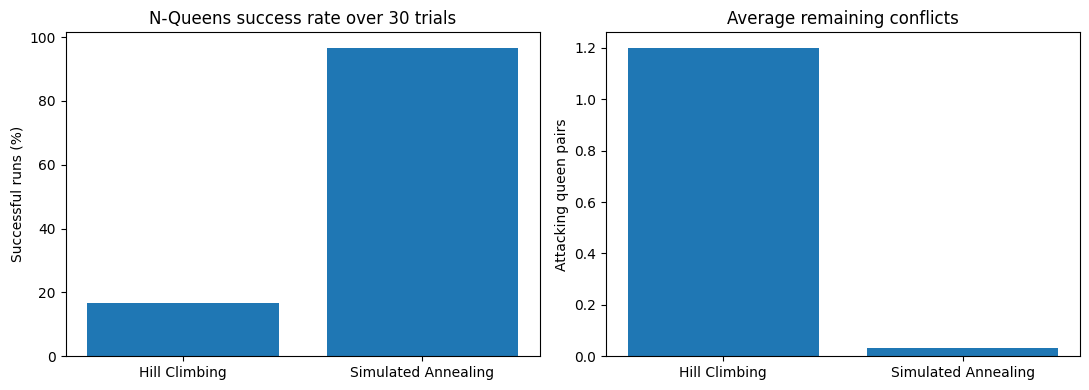

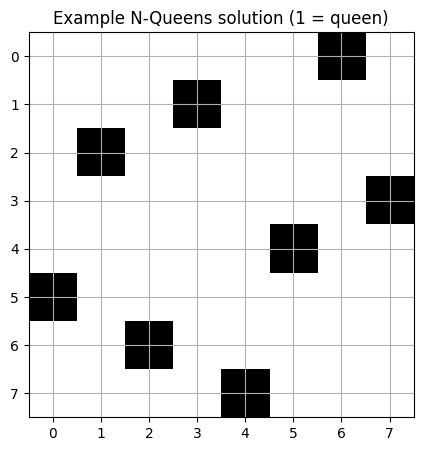

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(local_summary["algorithm"], local_summary["success_rate"])
axes[0].set_title("N-Queens success rate over 30 trials")
axes[0].set_ylabel("Successful runs (%)")
axes[1].bar(local_summary["algorithm"], local_summary["average_final_conflicts"])
axes[1].set_title("Average remaining conflicts")
axes[1].set_ylabel("Attacking queen pairs")
plt.tight_layout()
plt.show()

# Display one valid solution if the experiment found one.
solved_runs = local_results[(local_results["algorithm"] == "Simulated Annealing") & (local_results["solved"])]
if len(solved_runs):
    example = simulated_annealing(n=N_QUEENS, seed=RANDOM_SEED + int(solved_runs.iloc[0]["trial"]) - 1)
    board = np.zeros((N_QUEENS, N_QUEENS))
    for col, row in enumerate(example["state"]):
        board[row, col] = 1
    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap="Greys", vmin=0, vmax=1)
    plt.xticks(range(N_QUEENS)); plt.yticks(range(N_QUEENS))
    plt.grid(True)
    plt.title("Example N-Queens solution (1 = queen)")
    plt.show()
else:
    print("No solution found in this displayed trial; the success-rate table summarizes all trials.")

## 8. Constraint Satisfaction Problem: Australia map colouring

A CSP consists of variables, domains and constraints. Here, each Australian region is a variable, the available colours form its domain, and neighbouring regions must have different colours.

We compare:

1. **Basic Backtracking:** assigns values one at a time and backtracks when a constraint is violated.
2. **Backtracking with MRV and Forward Checking:** chooses the unassigned variable with the fewest remaining legal values (Minimum Remaining Values) and removes inconsistent colours from neighbouring domains after each assignment.



In [32]:
australia_neighbors = {
    "WA": {"NT", "SA"},
    "NT": {"WA", "SA", "Q"},
    "SA": {"WA", "NT", "Q", "NSW", "V"},
    "Q": {"NT", "SA", "NSW"},
    "NSW": {"Q", "SA", "V"},
    "V": {"SA", "NSW"},
    "T": set(),
}
VARIABLES = list(australia_neighbors)
COLORS = ["Red", "Green", "Blue"]


def is_consistent(variable, color, assignment):
    return all(assignment.get(neighbor) != color for neighbor in australia_neighbors[variable])


def basic_backtracking():
    assignment = {}
    stats = {"assignments": 0, "backtracks": 0}
    def backtrack():
        if len(assignment) == len(VARIABLES):
            return assignment.copy()
        variable = next(v for v in VARIABLES if v not in assignment)
        for color in COLORS:
            stats["assignments"] += 1
            if is_consistent(variable, color, assignment):
                assignment[variable] = color
                result = backtrack()
                if result is not None:
                    return result
                del assignment[variable]
        stats["backtracks"] += 1
        return None
    solution = backtrack()
    return solution, stats


def mrv_forward_checking():
    assignment = {}
    domains = {v: COLORS.copy() for v in VARIABLES}
    stats = {"assignments": 0, "backtracks": 0}
    def backtrack():
        if len(assignment) == len(VARIABLES):
            return assignment.copy()
        unassigned = [v for v in VARIABLES if v not in assignment]
        variable = min(unassigned, key=lambda v: (len(domains[v]), VARIABLES.index(v)))
        for color in domains[variable][:]:
            stats["assignments"] += 1
            if is_consistent(variable, color, assignment):
                assignment[variable] = color
                changed = {}
                failed = False
                for neighbor in australia_neighbors[variable]:
                    if neighbor not in assignment and color in domains[neighbor]:
                        changed[neighbor] = domains[neighbor].copy()
                        domains[neighbor].remove(color)
                        if not domains[neighbor]:
                            failed = True
                            break
                if not failed:
                    result = backtrack()
                    if result is not None:
                        return result
                for neighbor, old_domain in changed.items():
                    domains[neighbor] = old_domain
                del assignment[variable]
        stats["backtracks"] += 1
        return None
    solution = backtrack()
    return solution, stats

csp_rows = []
for name, solver in [("Backtracking", basic_backtracking), ("MRV + Forward Checking", mrv_forward_checking)]:
    t0 = time.perf_counter()
    solution, stats = solver()
    elapsed = (time.perf_counter() - t0) * 1000
    csp_rows.append({"algorithm": name, "solution_found": solution is not None,
                     "assignments_tried": stats["assignments"],
                     "backtracks": stats["backtracks"], "time_ms": elapsed})
    print(name, "solution:", solution)
    if solution:
        assert all(solution[a] != solution[b] for a in VARIABLES for b in australia_neighbors[a])

csp_comparison = pd.DataFrame(csp_rows)
display(csp_comparison.round(4))

Backtracking solution: {'WA': 'Red', 'NT': 'Green', 'SA': 'Blue', 'Q': 'Red', 'NSW': 'Green', 'V': 'Red', 'T': 'Red'}
MRV + Forward Checking solution: {'WA': 'Red', 'NT': 'Green', 'SA': 'Blue', 'Q': 'Red', 'NSW': 'Green', 'V': 'Red', 'T': 'Red'}


,algorithm,solution_found,assignments_tried,backtracks,time_ms
0,Backtracking,True,11,0,0.0631
1,MRV + Forward Checking,True,7,0,0.2520


## 9. Overall observations

Use the tables above to write observations based on the actual output from your run. The following points explain how to interpret the results:

- BFS guarantees the minimum number of edges in an unweighted graph, but it does not minimize the experimental edge cost.
- DFS can reach a goal without exploring the whole graph, but its returned route depends on traversal order and is not guaranteed to be optimal.
- UCS considers accumulated cost and returns a minimum-cost route for non-negative edge weights.
- Greedy Best-First Search is guided by the heuristic, but it may choose a route with a higher final cost.
- A* combines the cost already paid and the estimated remaining cost. With the admissible heuristic used here, it should match UCS's optimal path cost.
- Hill Climbing can stop at a local optimum. 
- MRV and Forward Checking can reduce unnecessary CSP exploration by selecting a constrained variable early and detecting empty domains before deeper recursion.


In [33]:
# Sanity checks for key properties of the experiment.
ucs_cost = next(r["path_cost"] for r in graph_results if r["algorithm"] == "UCS")
a_star_cost = next(r["path_cost"] for r in graph_results if r["algorithm"] == "A*")
assert a_star_cost == ucs_cost, "A* and UCS should return the same optimal cost with this admissible heuristic."
assert all(row["solution_found"] for row in csp_rows), "Both CSP methods should find a valid colouring."
assert all(queen_conflicts([0, 4, 7, 5, 2, 6, 1, 3]) == 0 for _ in [0])
print("All validation checks passed.")

All validation checks passed.




## 10.Conclusion

Different search strategies were evaluated across standard benchmarks:
* **Graph Search:** Contrasted minimum-edge vs. minimum-cost routes, with heuristics guiding informed search.
* **Local Search:** Demonstrated how random restarts and probabilistic moves avoid local optima.
* **CSP:** Showed that variable ordering and forward checking improve solving efficiency.

No single algorithm fits all tasks; selection depends on the problem type (route finding, optimization, or constraint satisfaction) and heuristic quality.

## References

1. NetworkX Documentation, `karate_club_graph`: https://networkx.org
2. Zachary, W. W. (1977). *An Information Flow Model for Conflict and Fission in Small Groups*. Journal of Anthropological Research, 33(4), 452–473.
3. Russell, S., & Norvig, P. *Artificial Intelligence: A Modern Approach*.
4. Python 3 Documentation: https://python.org
